# Блок 8. Глубокое обучение и архитектура нейросетей
## Занятие 3. Функции активации: Step, Sigmoid, Tanh, ReLU, Leaky ReLU

## Цель занятия

На занятии 1 мы разобрали один искусственный нейрон.  
На занятии 2 мы собрали простую многослойную сеть и выполнили Forward Pass.

Сегодня подробно изучаем важнейший элемент нейросети:

```text
функцию активации
```

---

## Что такое функция активации

Нейрон сначала считает взвешенную сумму:

```text
z = x1*w1 + x2*w2 + ... + xn*wn + b
```

Затем применяет функцию активации:

```text
a = activation(z)
```

Без функции активации многослойная сеть превращается почти в одну большую линейную формулу.

Функция активации добавляет нелинейность.  
Именно нелинейность позволяет нейросети решать сложные задачи.

---

## Зачем нужна нелинейность

Если использовать только линейные операции:

```text
Linear → Linear → Linear
```

то даже много слоёв можно свернуть в один линейный слой.

Но если добавить активации:

```text
Linear → ReLU → Linear → Sigmoid
```

сеть начинает моделировать сложные зависимости:

- изображения;
- текст;
- временные ряды;
- медицинские данные;
- поведение пользователей;
- сигналы и сенсоры.

---

## Основные функции активации занятия

| Функция | Диапазон | Где используется |
|---|---:|---|
| Step | 0 или 1 | простое объяснение классификации |
| Sigmoid | от 0 до 1 | вероятность, бинарная классификация |
| Tanh | от -1 до 1 | старые RNN, нормализованные сигналы |
| ReLU | от 0 до +∞ | скрытые слои современных сетей |
| Leaky ReLU | почти от -∞ до +∞ | борьба с «умирающими» ReLU |

---

## Важное понятие: производная

Во время обучения нейросеть обновляет веса.

Для этого используется градиентный спуск.  
А градиентный спуск зависит от производных.

Поэтому важно понимать не только саму функцию активации, но и её производную.

---

## Связь с будущими занятиями

Функции активации будут использоваться дальше:

- в Backpropagation;
- в PyTorch;
- в CNN;
- в RNN;
- в LSTM;
- в Transformer;
- в финальном проекте блока 8.

---

## Связь с дипломом

В дипломном проекте студент должен уметь объяснить:

- почему в скрытом слое используется ReLU;
- почему на выходе бинарной классификации используется Sigmoid;
- почему Softmax используется в многоклассовой классификации;
- почему неправильная функция активации может ухудшить обучение.

---

## GitHub Workflow занятия

```bash
git checkout main
git pull origin main
git checkout -b feature/block8-lesson03-activations

git add .
git commit -m "feat: add block8 lesson03 activation functions"
git push -u origin feature/block8-lesson03-activations
```

---

## Задача урока для переноса в VS Code

Создать файл:

```text
src/activations.py
```

Реализовать функции:

```python
step(z)
sigmoid(z)
tanh(z)
relu(z)
leaky_relu(z, alpha=0.01)
sigmoid_derivative(z)
tanh_derivative(z)
relu_derivative(z)
leaky_relu_derivative(z, alpha=0.01)
```

Добавить `assert`-проверки и небольшой запуск в `main.py`.


Сначала изучите SOLVED-ноутбук вместе с преподавателем. Затем выполните TODO-версию самостоятельно.

## Ячейка 1. TODO: импорт библиотек

### Алгоритм

1. Импортируйте `numpy`.
2. Импортируйте `pandas`.
3. Импортируйте `matplotlib.pyplot`.
4. Настройте `np.random.seed(42)`.
5. Проверьте импорты через `assert`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from activations import *

np.random.seed(42)

print("Библиотеки подключены")
print("NumPy version:", np.__version__)

assert np is not None
assert pd is not None
assert plt is not None

Библиотеки подключены
NumPy version: 2.5.4


## Ячейка 2. TODO: диапазон входных значений z

### Алгоритм

1. Создайте `z_values` от -6 до 6.
2. Постройте график линейного выхода.
3. Выведите минимум, максимум и количество точек.
4. Проверьте размер через `assert`.

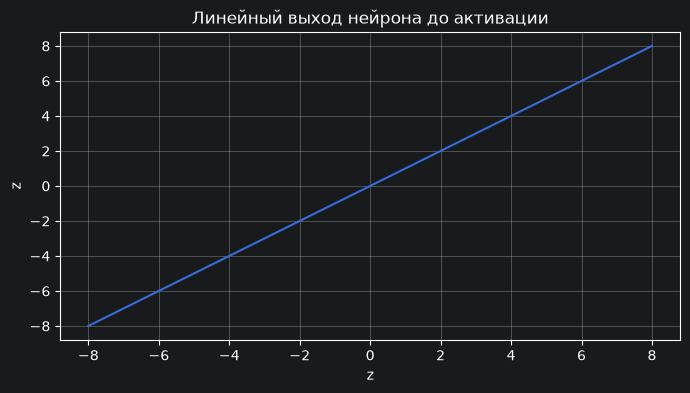

Dots count: 400
Minimum: -8.0
Maximum: 8.0


In [2]:
# TODO: создайте z_values через np.linspace
z_values = np.linspace(-8, 8, 400)
# TODO: постройте график z_values против z_values
plt.figure(figsize=(8,4))
plt.plot(z_values, z_values)
# TODO: добавьте title, xlabel, ylabel, grid
plt.title("Линейный выход нейрона до активации")
plt.xlabel("z")
plt.ylabel("z")
plt.grid(True)
plt.show()
# TODO: выведите len, min, max
print("Dots count:", len(z_values))
print("Minimum:", z_values.min())
print("Maximum:", z_values.max())
# TODO: assert len(z_values) == 400

assert len(z_values) == 400
assert z_values.min() == -8
assert z_values.max() == 8

## Ячейка 3. TODO: Step Function

### Алгоритм

1. Создайте функцию `step(z)`.
2. Примените её к `z_values`.
3. Постройте график.
4. Проверьте функцию через `assert`.

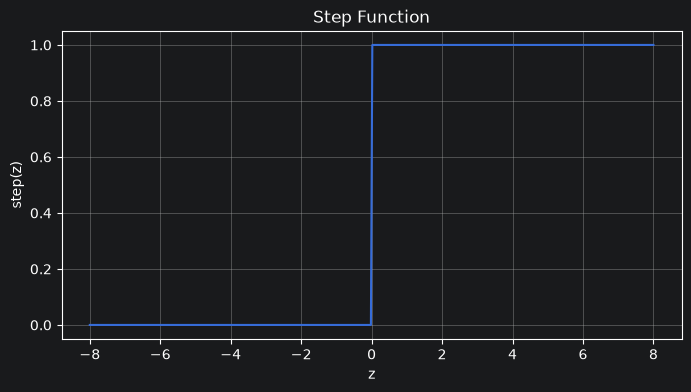

In [3]:
# TODO: создайте функцию step(z)

# TODO: создайте step_values
step_values = step(z_values)
# TODO: постройте график Step Function
plt.figure(figsize=(8,4))
plt.plot(z_values, step_values)
plt.title("Step Function")
plt.xlabel("z")
plt.ylabel("step(z)")
plt.grid(True)
plt.show()
# TODO: assert step(-1) == 0
assert step(-1) == 0
# TODO: assert step(0) == 1
assert step(0) == 1
# TODO: assert step(1) == 1
assert step(1) == 1

## Ячейка 4. TODO: Sigmoid и её производная

### Алгоритм

1. Создайте `sigmoid(z)`.
2. Создайте `sigmoid_derivative(z)`.
3. Посчитайте значения.
4. Постройте графики.
5. Проверьте диапазон значений.

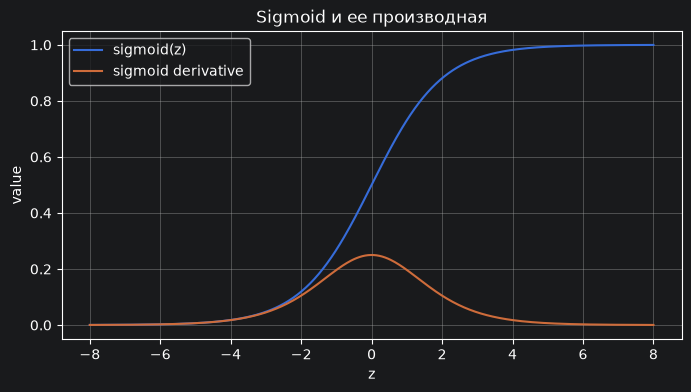

In [4]:
# TODO: создайте функцию sigmoid(z)

# TODO: создайте функцию sigmoid_derivative(z)

# TODO: создайте sigmoid_values
sigmoid_values = sigmoid(z_values)
# TODO: создайте sigmoid_grad
sigmoid_grad = sigmoid_derivative(z_values)
# TODO: постройте графики sigmoid и производной
plt.figure(figsize=(8,4))
plt.plot(z_values, sigmoid_values, label="sigmoid(z)")
plt.plot(z_values, sigmoid_grad, label="sigmoid derivative")
plt.title("Sigmoid и ее производная")
plt.xlabel("z")
plt.ylabel("value")
plt.grid(True)
plt.legend()
plt.show()
# TODO: assert sigmoid(0) почти равен 0.5
assert round(float(sigmoid(0)),4 ) == 0.5
assert sigmoid_values.min() > 0
assert sigmoid_values.max() < 1
assert sigmoid_grad.max() <= 0.25 + 1e-9
# TODO: assert sigmoid_values.min() > 0

## Ячейка 5. TODO: Tanh и её производная

### Алгоритм

1. Создайте `tanh(z)`.
2. Создайте `tanh_derivative(z)`.
3. Посчитайте значения.
4. Постройте графики.
5. Проверьте значения через `assert`.

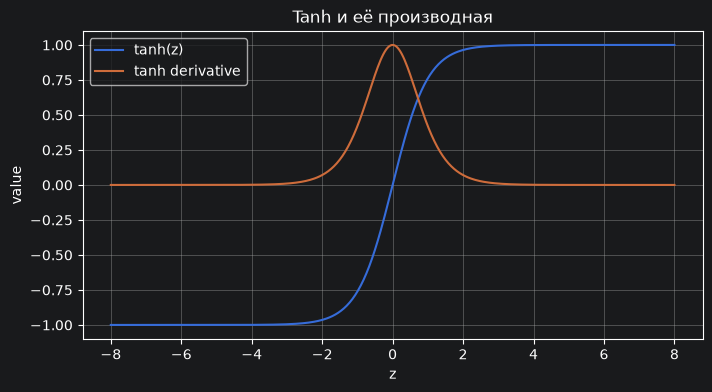

In [5]:
# TODO: создайте функцию tanh(z)

# TODO: создайте функцию tanh_derivative(z)

# TODO: создайте tanh_values
tanh_values = tanh(z_values)

# TODO: создайте tanh_grad
tanh_grad = tanh_derivative(z_values)
# TODO: постройте графики tanh и производной

plt.figure(figsize=(8, 4))
plt.plot(z_values, tanh_values, label="tanh(z)")
plt.plot(z_values, tanh_grad, label="tanh derivative")
plt.title("Tanh и её производная")
plt.xlabel("z")
plt.ylabel("value")
plt.grid(True)
plt.legend()
plt.show()
# TODO: assert tanh(0) почти равен 0
assert round(float(tanh(0)), 4) == 0
# TODO: assert tanh_derivative(0) почти равен 1
assert tanh_values.min() > -1
assert tanh_values.max() < 1
assert round(float(tanh_derivative(0)), 4) == 1

## Ячейка 6. TODO: ReLU и её производная

### Алгоритм

1. Создайте `relu(z)`.
2. Создайте `relu_derivative(z)`.
3. Посчитайте значения.
4. Постройте графики.
5. Проверьте ReLU через `assert`.

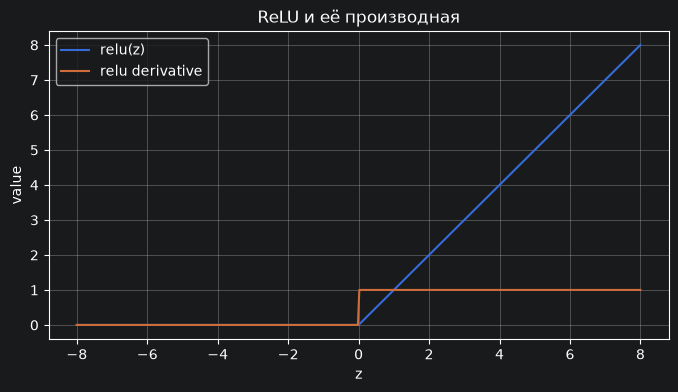

In [6]:
# TODO: создайте функцию relu(z)

# TODO: создайте функцию relu_derivative(z)

# TODO: создайте relu_values
relu_values = relu(z_values)

# TODO: создайте relu_grad
relu_grad = relu_derivative(z_values)

# TODO: постройте графики ReLU и производной
plt.figure(figsize=(8, 4))
plt.plot(z_values, relu_values, label="relu(z)")
plt.plot(z_values, relu_grad, label="relu derivative")
plt.title("ReLU и её производная")
plt.xlabel("z")
plt.ylabel("value")
plt.grid(True)
plt.legend()
plt.show()
# TODO: assert relu(-5) == 0
assert relu(-5) == 0
assert relu(0) == 0
# TODO: assert relu(3) == 3
assert relu(3) == 3
assert set(np.unique(relu_grad)).issubset({0, 1})

## Ячейка 7. TODO: Leaky ReLU и сравнение с ReLU

### Алгоритм

1. Создайте `leaky_relu(z, alpha=0.01)`.
2. Создайте `leaky_relu_derivative(z, alpha=0.01)`.
3. Посчитайте значения.
4. Постройте сравнение ReLU и Leaky ReLU.
5. Проверьте отрицательные значения.

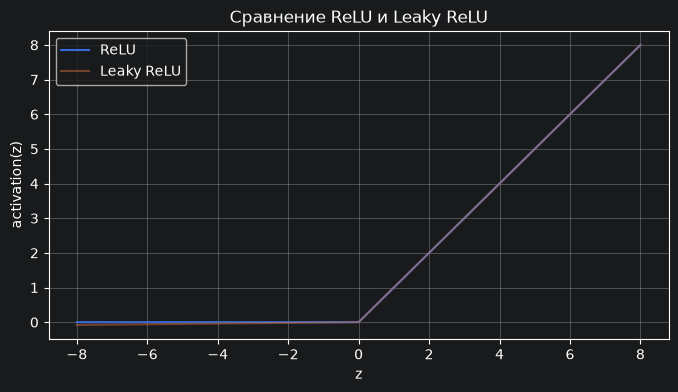

In [15]:
# TODO: создайте функцию leaky_relu(z, alpha=0.01)

# TODO: создайте функцию leaky_relu_derivative(z, alpha=0.01)

# TODO: создайте leaky_values
leaky_values = leaky_relu(z_values)

# TODO: создайте leaky_grad
leaky_grad = leaky_relu_derivative(z_values)
# TODO: постройте сравнение ReLU и Leaky ReLU
plt.figure(figsize=(8, 4))
plt.plot(z_values, relu_values, label="ReLU")
plt.plot(z_values, leaky_values, label="Leaky ReLU", alpha=0.5)
plt.title("Сравнение ReLU и Leaky ReLU")
plt.xlabel("z")
plt.ylabel("activation(z)")
plt.grid(True)
plt.legend()
plt.show()
# TODO: assert leaky_relu(-10) < 0
assert leaky_relu(-10) < 0
# TODO: assert leaky_relu(5) == 5
assert leaky_relu(5) == 5

## Ячейка 8. TODO: сравнительная таблица функций активации

### Алгоритм

1. Создайте `z_test`.
2. Примените все функции активации.
3. Соберите результат в `comparison`.
4. Покажите таблицу.
5. Проверьте размер таблицы.

In [16]:
# TODO: создайте z_test
z_test = np.array([-3, -1, 0, 1, 3], dtype=float)

# TODO: создайте DataFrame comparison
comparison = pd.DataFrame({
    "z": z_test,
    "Step": step(z_test),
    "Sigmoid": np.round(sigmoid(z_test), 3),
    "Tanh": np.round(tanh(z_test), 3),
    "ReLU": relu(z_test),
    "Leaky ReLU": np.round(leaky_relu(z_test), 3)
})
# TODO: добавьте колонки Step, Sigmoid, Tanh, ReLU, Leaky ReLU

# TODO: покажите comparison через display
display(comparison)
# TODO: assert comparison.shape == (5, 6)
assert comparison.shape == (5, 6)
assert comparison.loc[comparison["z"] == 0, "Sigmoid"].iloc[0] == 0.5
assert comparison.loc[comparison["z"] == -3, "ReLU"].iloc[0] == 0

,z,Step,Sigmoid,Tanh,ReLU,Leaky ReLU
0,-3.0,0,0.047,-0.995,0.0,-0.03
1,-1.0,0,0.269,-0.762,0.0,-0.01
2,0.0,1,0.500,0.000,0.0,0.00
3,1.0,1,0.731,0.762,1.0,1.00
4,3.0,1,0.953,0.995,3.0,3.00


## Ячейка 9. TODO: влияние функции активации на выход нейрона

### Алгоритм

1. Создайте мини-датасет студентов.
2. Создайте веса `w` и смещение `b`.
3. Посчитайте `z_students`.
4. Примените разные функции активации.
5. Постройте график.

,student,z,sigmoid,tanh,relu,leaky_relu
0,1,3.20,0.961,0.997,3.20,3.200
1,2,2.05,0.886,0.967,2.05,2.050
2,3,-0.90,0.289,-0.716,0.00,-0.009
3,4,0.25,0.562,0.245,0.25,0.250
4,5,3.40,0.968,0.998,3.40,3.400
5,6,-1.55,0.175,-0.914,0.00,-0.016


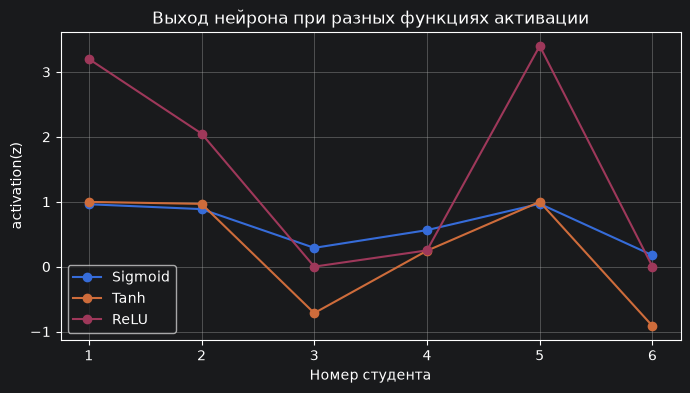

In [17]:
# TODO: создайте students
students = np.array([
    [0.9, 0.9, 0.2],
    [0.7, 0.8, 0.5],
    [0.2, 0.3, 0.8],
    [0.4, 0.5, 0.7],
    [1.0, 0.95, 0.3],
    [0.1, 0.2, 0.9]
])
# TODO: создайте w
w = np.array([2.0, 3.0, -1.5])

# TODO: создайте b
b = -1.0
# TODO: посчитайте z_students
z_students = students @ w + b
# TODO: создайте student_result
student_result = pd.DataFrame({
    "student": np.arange(1, len(students) + 1),
    "z": np.round(z_students, 3),
    "sigmoid": np.round(sigmoid(z_students), 3),
    "tanh": np.round(tanh(z_students), 3),
    "relu": np.round(relu(z_students), 3),
    "leaky_relu": np.round(leaky_relu(z_students), 3)
})
# TODO: покажите student_result
display(student_result)
# TODO: постройте график для нескольких активаций
plt.figure(figsize=(8, 4))
plt.plot(student_result["student"], student_result["sigmoid"], marker="o", label="Sigmoid")
plt.plot(student_result["student"], student_result["tanh"], marker="o", label="Tanh")
plt.plot(student_result["student"], student_result["relu"], marker="o", label="ReLU")
plt.title("Выход нейрона при разных функциях активации")
plt.xlabel("Номер студента")
plt.ylabel("activation(z)")
plt.grid(True)
plt.legend()
plt.show()
# TODO: assert len(z_students) == len(students)
assert len(z_students) == len(students)
assert student_result["sigmoid"].between(0, 1).all()

## Ячейка 10. TODO: итоговый отчёт и рекомендации

### Алгоритм

1. Создайте словарь `activation_recommendations`.
2. Создайте `lesson_report`.
3. Выведите рекомендации.
4. Выведите GitHub-команды.
5. Проверьте отчёт через `assert`.

In [18]:
activation_recommendations = {
    "Step": "подходит только для объяснения идеи порога, редко используется в обучаемых сетях",
    "Sigmoid": "удобна на выходе бинарной классификации как вероятность",
    "Tanh": "может использоваться в последовательных моделях и нормализованных сигналах",
    "ReLU": "основной выбор для скрытых слоёв многих нейросетей",
    "Leaky ReLU": "полезна, если ReLU зануляет слишком много нейронов"
}

lesson_report = {
    "topic": "Функции активации",
    "functions": list(activation_recommendations.keys()),
    "main_hidden_layer_choice": "ReLU",
    "binary_output_choice": "Sigmoid",
    "vscode_file": "src/activations.py"
}

print("Рекомендации:")
for name, recommendation in activation_recommendations.items():
    print("-", name + ":", recommendation)

print()
print("Итоговый отчёт занятия:")
for key, value in lesson_report.items():
    print(key, ":", value)

print()
print("GitHub:")
print("git checkout main")
print("git pull origin main")
print("git checkout -b feature/block8-lesson03-activations")
print("git add .")
print('git commit -m "feat: add block8 lesson03 activation functions"')
print("git push -u origin feature/block8-lesson03-activations")

assert "ReLU" in lesson_report["functions"]
assert "Sigmoid" in lesson_report["functions"]
assert len(activation_recommendations) == 5

Рекомендации:
- Step: подходит только для объяснения идеи порога, редко используется в обучаемых сетях
- Sigmoid: удобна на выходе бинарной классификации как вероятность
- Tanh: может использоваться в последовательных моделях и нормализованных сигналах
- ReLU: основной выбор для скрытых слоёв многих нейросетей
- Leaky ReLU: полезна, если ReLU зануляет слишком много нейронов

Итоговый отчёт занятия:
topic : Функции активации
functions : ['Step', 'Sigmoid', 'Tanh', 'ReLU', 'Leaky ReLU']
main_hidden_layer_choice : ReLU
binary_output_choice : Sigmoid
vscode_file : src/activations.py

GitHub:
git checkout main
git pull origin main
git checkout -b feature/block8-lesson03-activations
git add .
git commit -m "feat: add block8 lesson03 activation functions"
git push -u origin feature/block8-lesson03-activations


# Итог TODO-задания

Покажите преподавателю:

- график Step Function;
- график Sigmoid и производной;
- график Tanh и производной;
- график ReLU;
- сравнение ReLU и Leaky ReLU;
- сравнительную таблицу функций активации;
- пример влияния активации на выход нейрона;
- рекомендации по выбору функции активации;
- GitHub-коммит;
- файл `src/activations.py` в VS Code.